In [5]:
#Subiectul 1

import numpy as np
from hmmlearn import hmm

pi = np.array([0.25, 0.25, 0.25, 0.25])

B = np.array([
    [0.7, 0.2, 0.1],
    [0.2, 0.6, 0.2],
    [0.1, 0.3, 0.6],
    [0.5, 0.2, 0.3],
])

obs = np.array([[0], [1], [2], [2], [0]])

def rezolva_hmm(A, nume_subpunct):
    model = hmm.CategoricalHMM(n_components=4)
    model.startprob_ = pi
    model.transmat_ = A
    model.emissionprob_ = B

    log_prob, states = model.decode(obs, algorithm="viterbi")
    prob = np.exp(log_prob)
    camere = states + 1

    print(f"{nume_subpunct}")
    print(f"Cea mai probabilă secvență de camere: {camere.tolist()}")
    print(f"Probabilitatea comună P(X, O): {prob:.9f}\n")

A_a = np.array([
    [0.2, 0.4, 0.0, 0.4],
    [0.4, 0.2, 0.4, 0.0],
    [0.0, 0.4, 0.2, 0.4],
    [0.4, 0.0, 0.4, 0.2],
])

A_b = np.array([
    [0.0, 0.5, 0.0, 0.5],
    [0.5, 0.0, 0.5, 0.0],
    [0.0, 0.5, 0.0, 0.5],
    [0.5, 0.0, 0.5, 0.0],
])

rezolva_hmm(A_a, "Subpunctul a")
rezolva_hmm(A_b, "Subpunctul b")

Subpunctul a
Cea mai probabilă secvență de camere: [1, 2, 3, 4, 1]
Probabilitatea comună P(X, O): 0.000338688

Subpunctul b
Cea mai probabilă secvență de camere: [1, 2, 3, 4, 1]
Probabilitatea comună P(X, O): 0.000826875



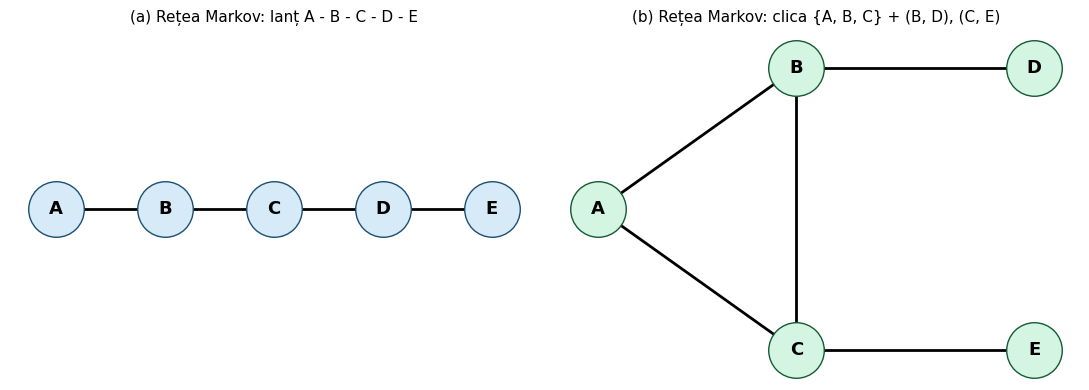

In [7]:
import networkx as nx
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

G_a = nx.Graph()
G_a.add_edges_from([('A', 'B'), ('B', 'C'), ('C', 'D'), ('D', 'E')])
pos_a = {'A': (0, 0), 'B': (1, 0), 'C': (2, 0), 'D': (3, 0), 'E': (4, 0)}

nx.draw(
    G_a, pos_a, ax=ax1, with_labels=True,
    node_size=1600, node_color='#D6EAF8', edgecolors='#1B4F72',
    font_size=13, font_weight='bold', width=2
)
ax1.set_title("(a) Rețea Markov: lanț A - B - C - D - E", fontsize=11, pad=12)

G_b = nx.Graph()
G_b.add_edges_from([('A', 'B'), ('B', 'C'), ('A', 'C'), ('B', 'D'), ('C', 'E')])
pos_b = {'A': (0, 0.5), 'B': (1, 1), 'C': (1, 0), 'D': (2.2, 1), 'E': (2.2, 0)}

nx.draw(
    G_b, pos_b, ax=ax2, with_labels=True,
    node_size=1600, node_color='#D5F5E3', edgecolors='#145A32',
    font_size=13, font_weight='bold', width=2
)
ax2.set_title("(b) Rețea Markov: clica {A, B, C} + (B, D), (C, E)", fontsize=11, pad=12)

plt.tight_layout()
plt.savefig("retele_markov_ex2.png", dpi=150, bbox_inches="tight")
plt.show()


(a) A posteriori după lotul 1: Beta(7, 23)
    Media a posteriori: 0.2333

(b) A posteriori după ambele loturi: Beta(10, 35)
    Media: 0.2222 (2/9), Varianța: 0.003757

(c) A posteriori doar cu lotul 2: Beta(5, 20)
    Media: 0.2000 (1/5), Varianța: 0.006154


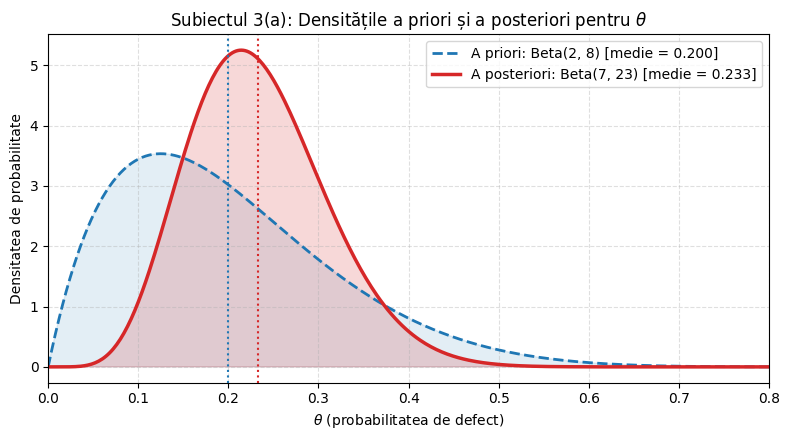

In [9]:
# Subiectul 3

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import beta

alpha_0, beta_0 = 2, 8

n1, k1 = 20, 5
alpha_1 = alpha_0 + k1
beta_1 = beta_0 + (n1 - k1)
media_1 = alpha_1 / (alpha_1 + beta_1)

print(f"(a) A posteriori după lotul 1: Beta({alpha_1}, {beta_1})")
print(f"    Media a posteriori: {media_1:.4f}")

n2, k2 = 15, 3

alpha_b = alpha_1 + k2
beta_b = beta_1 + (n2 - k2)
media_b = alpha_b / (alpha_b + beta_b)
var_b = beta.var(alpha_b, beta_b)

print(f"\n(b) A posteriori după ambele loturi: Beta({alpha_b}, {beta_b})")
print(f"    Media: {media_b:.4f} (2/9), Varianța: {var_b:.6f}")

alpha_c = alpha_0 + k2
beta_c = beta_0 + (n2 - k2)
media_c = alpha_c / (alpha_c + beta_c)
var_c = beta.var(alpha_c, beta_c)

print(f"\n(c) A posteriori doar cu lotul 2: Beta({alpha_c}, {beta_c})")
print(f"    Media: {media_c:.4f} (1/5), Varianța: {var_c:.6f}")

theta = np.linspace(0, 1, 500)
pdf_prior = beta.pdf(theta, alpha_0, beta_0)
pdf_post1 = beta.pdf(theta, alpha_1, beta_1)

plt.figure(figsize=(8, 4.5))
plt.plot(theta, pdf_prior, "--", color="#1f77b4", lw=2, label=f"A priori: Beta({alpha_0}, {beta_0}) [medie = 0.200]")
plt.fill_between(theta, pdf_prior, color="#1f77b4", alpha=0.12)

plt.plot(theta, pdf_post1, "-", color="#d62728", lw=2.5, label=f"A posteriori: Beta({alpha_1}, {beta_1}) [medie = {media_1:.3f}]")
plt.fill_between(theta, pdf_post1, color="#d62728", alpha=0.18)

plt.axvline(alpha_0 / (alpha_0 + beta_0), color="#1f77b4", linestyle=":", lw=1.5)
plt.axvline(media_1, color="#d62728", linestyle=":", lw=1.5)

plt.title("Subiectul 3(a): Densitățile a priori și a posteriori pentru $\\theta$")
plt.xlabel("$\\theta$ (probabilitatea de defect)")
plt.ylabel("Densitatea de probabilitate")
plt.xlim(0, 0.8)
plt.grid(True, linestyle="--", alpha=0.4)
plt.legend()
plt.tight_layout()
plt.savefig("inferenta_bayesiana_ex3.png", dpi=150, bbox_inches="tight")
plt.show()
